# SML & BDA Experiment 5
## Title - Hyperparameter Tuning for Machine Learning Models
### Name - Manan Chahal
### Roll No - 23102C0044

# Initialization

In [1]:
!pip install optuna


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler

print('All libraries imported successfully!')


All libraries imported successfully!


# Loading Dataset

In [3]:
# Load the Breast Cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

feature_names = data.feature_names
target_names  = data.target_names

print('Dataset: Breast Cancer Wisconsin')
print('Number of Samples  :', X.shape[0])
print('Number of Features :', X.shape[1])
print('Target Classes     :', list(target_names))
print('Class Distribution :', dict(zip(target_names, map(int, __import__("numpy").bincount(y)))))


Dataset: Breast Cancer Wisconsin
Number of Samples  : 569
Number of Features : 30
Target Classes     : [np.str_('malignant'), np.str_('benign')]
Class Distribution : {np.str_('malignant'): 212, np.str_('benign'): 357}


In [4]:
# Quick peek at the data as a DataFrame
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
print(df.head())


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

# Train-Test Split & Feature Scaling

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print('Training samples :', X_train.shape[0])
print('Testing  samples :', X_test.shape[0])


Training samples : 455
Testing  samples : 114


# Baseline Models (Before Hyperparameter Tuning)

In [6]:
# --- Decision Tree Baseline ---
dt_baseline = DecisionTreeClassifier(random_state=42)
dt_baseline.fit(X_train_sc, y_train)
dt_baseline_pred = dt_baseline.predict(X_test_sc)
dt_baseline_acc  = accuracy_score(y_test, dt_baseline_pred)

# --- Random Forest Baseline ---
rf_baseline = RandomForestClassifier(random_state=42)
rf_baseline.fit(X_train_sc, y_train)
rf_baseline_pred = rf_baseline.predict(X_test_sc)
rf_baseline_acc  = accuracy_score(y_test, rf_baseline_pred)

print('=== Baseline Accuracies (Default Hyperparameters) ===')
print('Decision Tree  : {:.4f} ({:.2f}%)'.format(dt_baseline_acc, dt_baseline_acc*100))
print('Random Forest  : {:.4f} ({:.2f}%)'.format(rf_baseline_acc, rf_baseline_acc*100))


=== Baseline Accuracies (Default Hyperparameters) ===
Decision Tree  : 0.9123 (91.23%)
Random Forest  : 0.9561 (95.61%)


In [7]:
print('Decision Tree Baseline - Classification Report:')
print(classification_report(y_test, dt_baseline_pred, target_names=target_names))


Decision Tree Baseline - Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



In [8]:
print('Random Forest Baseline - Classification Report:')
print(classification_report(y_test, rf_baseline_pred, target_names=target_names))


Random Forest Baseline - Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



# Hyperparameter Tuning with Optuna

## Decision Tree - Optuna Tuning

In [9]:
def dt_objective(trial):
    """Objective function for Decision Tree hyperparameter tuning."""
    params = {
        'criterion'        : trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'max_depth'        : trial.suggest_int('max_depth', 2, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf' : trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features'     : trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'random_state'     : 42
    }
    model = DecisionTreeClassifier(**params)
    score = cross_val_score(model, X_train_sc, y_train, cv=5, scoring='accuracy').mean()
    return score

# Create and run the Optuna study for Decision Tree
dt_study = optuna.create_study(direction='maximize', study_name='DecisionTree_Study')
dt_study.optimize(dt_objective, n_trials=100, show_progress_bar=False)

print('Decision Tree - Best Trial:')
print('  Best CV Accuracy : {:.4f}'.format(dt_study.best_value))
print('  Best Parameters  :', dt_study.best_params)


Decision Tree - Best Trial:
  Best CV Accuracy : 0.9341
  Best Parameters  : {'criterion': 'entropy', 'max_depth': 12, 'min_samples_split': 6, 'min_samples_leaf': 7, 'max_features': None}


In [10]:
# Train Decision Tree with best hyperparameters
dt_tuned = DecisionTreeClassifier(**dt_study.best_params)
dt_tuned.fit(X_train_sc, y_train)
dt_tuned_pred = dt_tuned.predict(X_test_sc)
dt_tuned_acc  = accuracy_score(y_test, dt_tuned_pred)

print('Decision Tree - Tuned Test Accuracy : {:.4f} ({:.2f}%)'.format(dt_tuned_acc, dt_tuned_acc*100))
print()
print('Decision Tree Tuned - Classification Report:')
print(classification_report(y_test, dt_tuned_pred, target_names=target_names))


Decision Tree - Tuned Test Accuracy : 0.9386 (93.86%)

Decision Tree Tuned - Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



## Random Forest - Optuna Tuning

In [11]:
def rf_objective(trial):
    """Objective function for Random Forest hyperparameter tuning."""
    params = {
        'n_estimators'     : trial.suggest_int('n_estimators', 50, 300),
        'criterion'        : trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'max_depth'        : trial.suggest_int('max_depth', 2, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf' : trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features'     : trial.suggest_categorical('max_features', ['sqrt', 'log2']),
        'bootstrap'        : trial.suggest_categorical('bootstrap', [True, False]),
        'random_state'     : 42
    }
    model = RandomForestClassifier(**params)
    score = cross_val_score(model, X_train_sc, y_train, cv=5, scoring='accuracy').mean()
    return score

# Create and run the Optuna study for Random Forest
rf_study = optuna.create_study(direction='maximize', study_name='RandomForest_Study')
rf_study.optimize(rf_objective, n_trials=100, show_progress_bar=False)

print('Random Forest - Best Trial:')
print('  Best CV Accuracy : {:.4f}'.format(rf_study.best_value))
print('  Best Parameters  :', rf_study.best_params)


Random Forest - Best Trial:
  Best CV Accuracy : 0.9714
  Best Parameters  : {'n_estimators': 94, 'criterion': 'entropy', 'max_depth': 19, 'min_samples_split': 3, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'bootstrap': False}


In [12]:
# Train Random Forest with best hyperparameters
rf_tuned = RandomForestClassifier(**rf_study.best_params)
rf_tuned.fit(X_train_sc, y_train)
rf_tuned_pred = rf_tuned.predict(X_test_sc)
rf_tuned_acc  = accuracy_score(y_test, rf_tuned_pred)

print('Random Forest - Tuned Test Accuracy : {:.4f} ({:.2f}%)'.format(rf_tuned_acc, rf_tuned_acc*100))
print()
print('Random Forest Tuned - Classification Report:')
print(classification_report(y_test, rf_tuned_pred, target_names=target_names))


Random Forest - Tuned Test Accuracy : 0.9649 (96.49%)

Random Forest Tuned - Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.93      0.95        42
      benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



# Analysis & Visualization

## Before vs After Accuracy Comparison

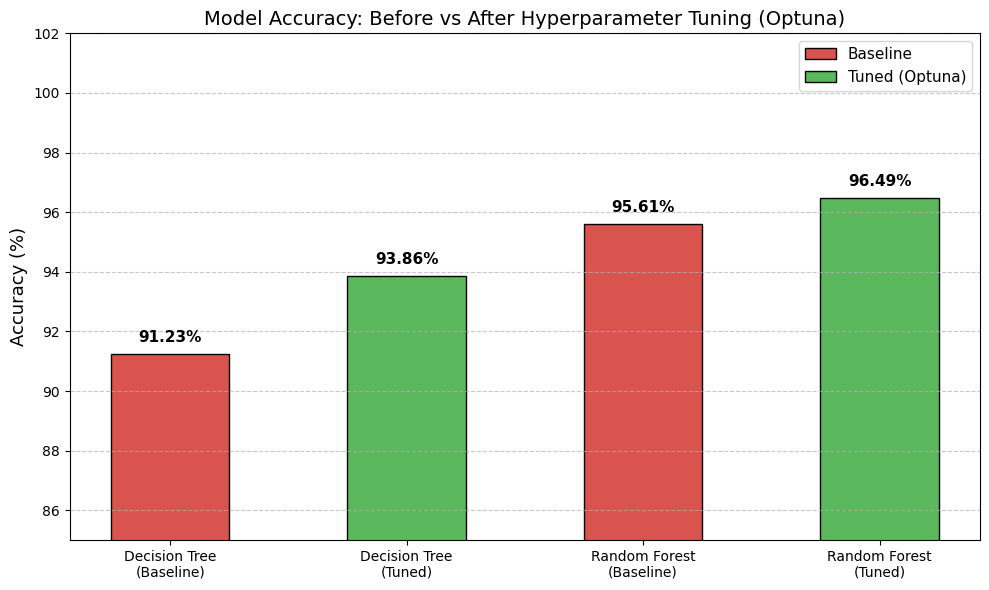


=== Improvement Summary ===
Decision Tree improvement : +2.63%
Random Forest improvement : +0.88%


In [13]:
models      = ['Decision Tree\n(Baseline)', 'Decision Tree\n(Tuned)',
               'Random Forest\n(Baseline)', 'Random Forest\n(Tuned)']
accuracies  = [dt_baseline_acc, dt_tuned_acc, rf_baseline_acc, rf_tuned_acc]
colors      = ['#d9534f', '#5cb85c', '#d9534f', '#5cb85c']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(models, [a * 100 for a in accuracies], color=colors,
              edgecolor='black', width=0.5)

for bar, acc in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        '{:.2f}%'.format(acc*100),
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )

ax.set_ylim(85, 102)
ax.set_ylabel('Accuracy (%)', fontsize=13)
ax.set_title('Model Accuracy: Before vs After Hyperparameter Tuning (Optuna)', fontsize=14)
ax.grid(axis='y', linestyle='--', alpha=0.7)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#d9534f', edgecolor='black', label='Baseline'),
                   Patch(facecolor='#5cb85c', edgecolor='black', label='Tuned (Optuna)')]
ax.legend(handles=legend_elements, fontsize=11)

plt.tight_layout()
plt.show()

print('\n=== Improvement Summary ===')
dt_improvement = (dt_tuned_acc - dt_baseline_acc) * 100
rf_improvement = (rf_tuned_acc - rf_baseline_acc) * 100
print('Decision Tree improvement : {:+.2f}%'.format(dt_improvement))
print('Random Forest improvement : {:+.2f}%'.format(rf_improvement))


## Optuna Optimization History

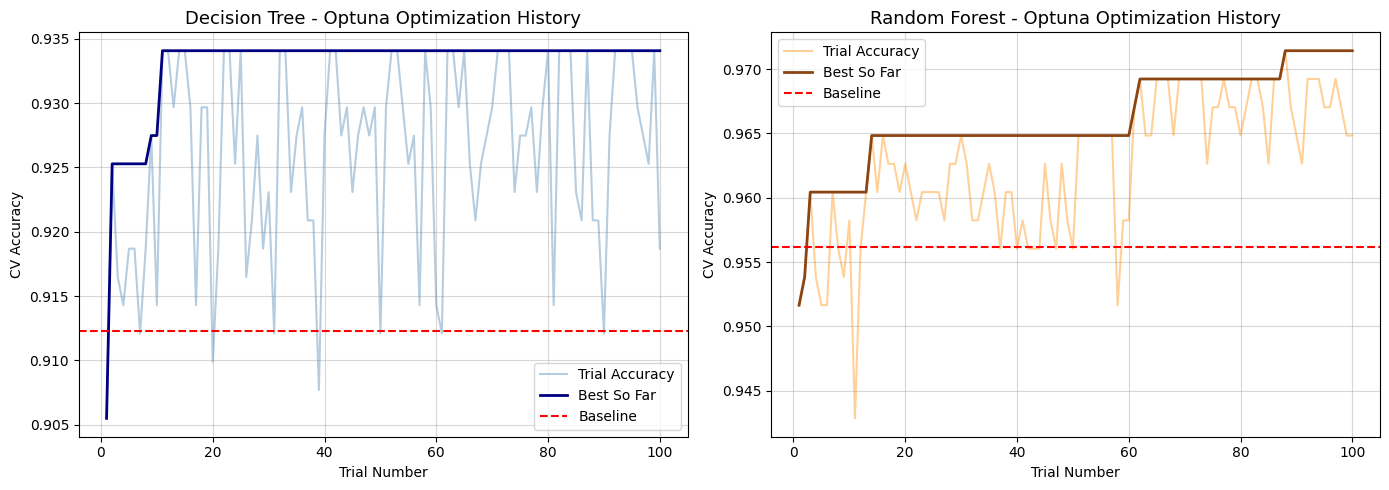

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Decision Tree optimization history
dt_trials  = [t.number + 1 for t in dt_study.trials]
dt_values  = [t.value for t in dt_study.trials]
dt_best    = [max(dt_values[:i+1]) for i in range(len(dt_values))]

axes[0].plot(dt_trials, dt_values, alpha=0.4, color='steelblue', label='Trial Accuracy')
axes[0].plot(dt_trials, dt_best,   color='navy', linewidth=2, label='Best So Far')
axes[0].axhline(y=dt_baseline_acc, color='red', linestyle='--', label='Baseline')
axes[0].set_title('Decision Tree - Optuna Optimization History', fontsize=13)
axes[0].set_xlabel('Trial Number')
axes[0].set_ylabel('CV Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.5)

# Random Forest optimization history
rf_trials  = [t.number + 1 for t in rf_study.trials]
rf_values  = [t.value for t in rf_study.trials]
rf_best    = [max(rf_values[:i+1]) for i in range(len(rf_values))]

axes[1].plot(rf_trials, rf_values, alpha=0.4, color='darkorange', label='Trial Accuracy')
axes[1].plot(rf_trials, rf_best,   color='saddlebrown', linewidth=2, label='Best So Far')
axes[1].axhline(y=rf_baseline_acc, color='red', linestyle='--', label='Baseline')
axes[1].set_title('Random Forest - Optuna Optimization History', fontsize=13)
axes[1].set_xlabel('Trial Number')
axes[1].set_ylabel('CV Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.5)

plt.tight_layout()
plt.show()


## Hyperparameter Importance (Random Forest)

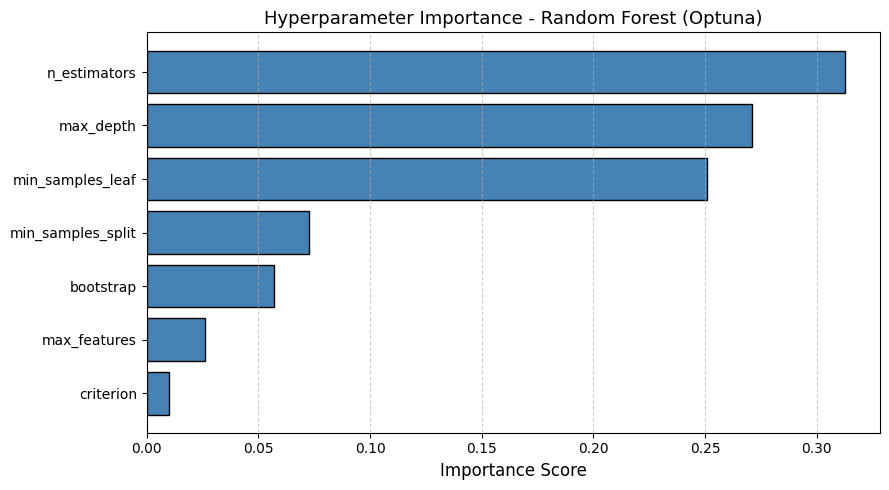

In [15]:
# Hyperparameter importance using Optuna built-in utility
rf_importance = optuna.importance.get_param_importances(rf_study)

params_list     = list(rf_importance.keys())
importance_list = list(rf_importance.values())

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(params_list[::-1], importance_list[::-1], color='steelblue', edgecolor='black')
ax.set_xlabel('Importance Score', fontsize=12)
ax.set_title('Hyperparameter Importance - Random Forest (Optuna)', fontsize=13)
ax.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Confusion Matrices

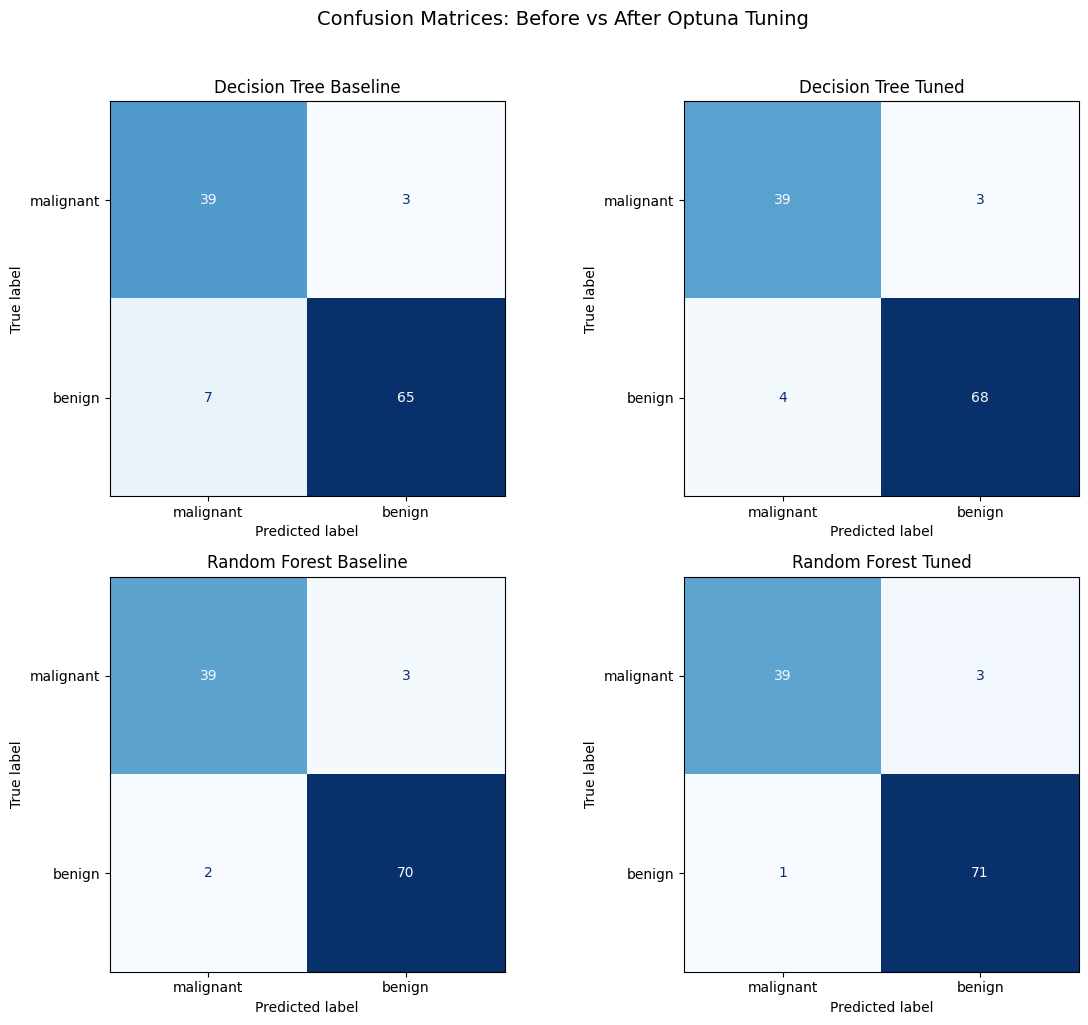

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

titles = [
    ('Decision Tree Baseline', dt_baseline_pred),
    ('Decision Tree Tuned',    dt_tuned_pred),
    ('Random Forest Baseline', rf_baseline_pred),
    ('Random Forest Tuned',    rf_tuned_pred)
]

for ax, (title, pred) in zip(axes.ravel(), titles):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title, fontsize=12)

plt.suptitle('Confusion Matrices: Before vs After Optuna Tuning', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


# Final Summary

In [18]:
summary_data = {
    'Model'            : ['Decision Tree (Baseline)', 'Decision Tree (Tuned)',
                          'Random Forest (Baseline)', 'Random Forest (Tuned)'],
    'Test Accuracy (%)': [round(dt_baseline_acc*100, 2), round(dt_tuned_acc*100, 2),
                          round(rf_baseline_acc*100, 2), round(rf_tuned_acc*100, 2)],
    'Improvement (%)' : ['-',
                          '+{:.2f}'.format((dt_tuned_acc - dt_baseline_acc)*100),
                          '-',
                          '+{:.2f}'.format((rf_tuned_acc - rf_baseline_acc)*100)]
}

summary_df = pd.DataFrame(summary_data)
print('\n========== Experiment 5 - Final Results Summary ==========')
print(summary_df.to_string(index=False))
print('=' * 58)
print()
print('Best Decision Tree hyperparameters found by Optuna:')
for k, v in dt_study.best_params.items():
    print('  {}: {}'.format(k, v))
print()
print('Best Random Forest hyperparameters found by Optuna:')
for k, v in rf_study.best_params.items():
    print('  {}: {}'.format(k, v))



========== Experiment 5 - Final Results Summary ==========
                   Model  Test Accuracy (%) Improvement (%)
Decision Tree (Baseline)              91.23               -
   Decision Tree (Tuned)              93.86           +2.63
Random Forest (Baseline)              95.61               -
   Random Forest (Tuned)              96.49           +0.88

Best Decision Tree hyperparameters found by Optuna:
  criterion: entropy
  max_depth: 12
  min_samples_split: 6
  min_samples_leaf: 7
  max_features: None

Best Random Forest hyperparameters found by Optuna:
  n_estimators: 94
  criterion: entropy
  max_depth: 19
  min_samples_split: 3
  min_samples_leaf: 2
  max_features: sqrt
  bootstrap: False
